In [1]:
import logging

import numpy as np
import optimistix as optx
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec

from atmodeller import (
    InteriorAtmosphere,
    Planet,
    SolverParameters,
    Species,
    SpeciesCollection,
    debug_logger,
)
from atmodeller.eos import get_eos_models
from atmodeller.solubility import get_solubility_models
from atmodeller.thermodata import IronWustiteBuffer

import plotly.graph_objects as go
from plotly.subplots import make_subplots
import plotly.io as pio
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import gridspec
from scipy.signal import savgol_filter


logger = debug_logger()
logger.setLevel(logging.INFO)
# For more output use DEBUG
# logger.setLevel(logging.DEBUG)

Atmodeller initialized with double precision (float64)


# Sub-Neptune (e.g. K2-18b) models from Bower et al. (2025)

The code blocks below must always be run, but then you can preferentially run only the models for ideal or real gases.

Parameters for the simulations

In [2]:
eos_models = get_eos_models()
sol_models = get_solubility_models()

# Gases 
H2O_gs = Species.create_gas(
    "H2O", 
    solubility=sol_models["H2O_peridotite_sossi23"]
    )
H2O_rgs = Species.create_gas(
    "H2O", 
    activity=eos_models["H2O_cork_holland98"],
    solubility=sol_models["H2O_peridotite_sossi23"]
    )

H2_gs = Species.create_gas(
    "H2", 
    solubility=sol_models["H2_basalt_hirschmann12"]
    )
H2_rgs = Species.create_gas(
    "H2", 
    activity=eos_models["H2_chabrier21"], 
    solubility=sol_models["H2_basalt_hirschmann12"]
    )

O2_g = Species.create_gas(
    "O2"
    )
O2_rg = Species.create_gas(
    "O2", 
    activity=eos_models["O2_cs_shi92"]
    )


CO2_gs = Species.create_gas(
    "CO2", solubility=sol_models["CO2_basalt_dixon95"]
)

CO2_rgs = Species.create_gas(
    "CO2", solubility=sol_models["CO2_basalt_dixon95"], activity=eos_models["CO2_cs_shi92"]
)

CO_gs = Species.create_gas(
    "CO", solubility=sol_models["CO_basalt_yoshioka19"]
)
CO_rgs = Species.create_gas(
    "CO", solubility=sol_models["CO_basalt_yoshioka19"], activity=eos_models["CO_cs_shi92"]
)

CH4_gs = Species.create_gas(
    "CH4", solubility=sol_models["CH4_basalt_ardia13"]
)
CH4_rgs = Species.create_gas(
    "CH4", solubility=sol_models["CH4_basalt_ardia13"], activity=eos_models["CH4_cs_shi92"]
)

N2_gs = Species.create_gas(
    "N2", solubility=sol_models["N2_basalt_libourel03"]
)
N2_rgs = Species.create_gas(
    "N2", solubility=sol_models["N2_basalt_libourel03"], activity=eos_models["N2_cs_saxena87"]
)

NH3_g = Species.create_gas("H3N")
NH3_rg = Species.create_gas("H3N", activity=eos_models["H3N_rk49_reid87"])


CHN_g = Species.create_gas("CHN")
CHN_rg = Species.create_gas("CHN", activity=eos_models["CHN_rk49_reid87"])

He_gs = Species.create_gas(
    "He", solubility=sol_models["He_basalt_jambon86"]
)
He_rgs = Species.create_gas(
    "He", solubility=sol_models["He_basalt_jambon86"], activity=eos_models["He_chabrier21"]
)


species_ideal = SpeciesCollection(
    (
        H2O_gs,
        H2_gs,
        O2_g,
        CO2_gs,
        CO_gs,
        CH4_gs,
        N2_gs,
        NH3_g,
        CHN_g,
        He_gs,
    )
)

species_real = SpeciesCollection(
    (
        H2O_rgs,
        H2_rgs,
        O2_rg,
        CO2_rgs,
        CO_rgs,
        CH4_rgs,
        N2_rgs,
        NH3_rg,
        CHN_rg,
        He_rgs,
    )
)

In [3]:
number_of_realisations = 50
surface_temperature = 3000  # K

# For simulations with fixed mass and surface radius:
planet_mass = 5.154e25
surface_radius = 1.1225e7  # using M-R relation from Hakim+2018
mantle_melt_fraction = 1  # 0.1

ALL_VALUES = []

RANDOM_SEED = 0
np.random.seed(RANDOM_SEED)

## Hydrogen fraction

Where does saturation occur

In [4]:
import numpy as np

# ===========================================================
# 1. Lodders (2009) solar composition mass fractions (wt%)
# ===========================================================
H_masspercent_lodders09  = 73.9
He_masspercent_lodders09 = 24.69
C_masspercent_lodders09  = 0.22
N_masspercent_lodders09  = 0.07
O_masspercent_lodders09  = 0.63

# Ratios relative to hydrogen (Solar)
C_H_RATIO_SOLAR  = C_masspercent_lodders09  / H_masspercent_lodders09
N_H_RATIO_SOLAR  = N_masspercent_lodders09  / H_masspercent_lodders09
O_H_RATIO_SOLAR  = O_masspercent_lodders09  / H_masspercent_lodders09
He_H_RATIO_SOLAR = He_masspercent_lodders09 / H_masspercent_lodders09


# ===========================================================
# 2. Function to get metal-enriched budgets
# ===========================================================
def get_enriched_budget(h_kg, metallicity_factor=100):
    """
    Returns C, N, O, and He masses based on solar H ratios,
    with C, N, O enriched by metallicity_factor × solar.
    He stays fixed at the solar He/H ratio.
    """
    return {
        "H":  h_kg,
        "C":  h_kg * C_H_RATIO_SOLAR  * metallicity_factor,
        "N":  h_kg * N_H_RATIO_SOLAR  * metallicity_factor,
        "He": h_kg * He_H_RATIO_SOLAR
    }


# ===========================================================
# 3. Hydrogen mass fraction range: 0.1% → 10% of total planet mass
# ===========================================================
number_of_realisations = 50   # choose as needed

# Hydrogen mass fractions between 0.001 and 0.10
H_mass_fraction = np.logspace(-3, -1, number_of_realisations)
fO2_log10_shifts = np.full(number_of_realisations, -3)

# Convert mass fraction → hydrogen mass in kg
h_kg = H_mass_fraction * planet_mass

mass_constraints = get_enriched_budget(h_kg, metallicity_factor=100)

In [5]:
sub_neptune = Planet(
    surface_temperature=surface_temperature,
    planet_mass=planet_mass,
    surface_radius=surface_radius,
    mantle_melt_fraction=mantle_melt_fraction,
)

<>:192: SyntaxWarning: invalid escape sequence '\D'
<>:192: SyntaxWarning: invalid escape sequence '\D'
/var/folders/l6/yw7hsmzx1czfjt3n32sfq_w00000gn/T/ipykernel_89308/2785349703.py:192: SyntaxWarning: invalid escape sequence '\D'
  ax.set_title(f"$\Delta$IW = {dIW}", fontsize=20)
[11:11:07 - atmodeller.classes             - INFO     ] - species = ('H2O_g: CombinedRealGas, SolubilityPowerLaw', 'H2_g: CombinedRealGas, SolubilityPowerLawLog10', 'O2_g: CombinedRealGas, NoSolubility', 'CO2_g: CombinedRealGas, _CO2_basalt_dixon95', 'CO_g: CombinedRealGas, _CO_basalt_yoshioka19', 'CH4_g: CombinedRealGas, _CH4_basalt_ardia13', 'N2_g: CombinedRealGas, _N2_basalt_libourel03', 'H3N_g: RedlichKwong49, NoSolubility', 'CHN_g: RedlichKwong49, NoSolubility', 'He_g: CombinedRealGas, SolubilityPowerLaw')
[11:11:07 - atmodeller.classes             - INFO     ] - Thermodynamic data requires temperatures between 200 K and 6000 K
[11:11:07 - atmodeller.classes             - INFO     ] - reactions = {0: '2

Starting simulation loop...
--- Processing dIW = -6 ---


[11:11:42 - atmodeller.classes             - INFO     ] - Solve complete: 1 (100.00%) successful model(s)
[11:11:42 - atmodeller.classes             - INFO     ] - Solver steps (max) = 88
[11:11:42 - atmodeller.output_core         - INFO     ] - Computing to_dataframes output
[11:11:42 - atmodeller.output_core         - INFO     ] - Computing asdict output
/var/folders/l6/yw7hsmzx1czfjt3n32sfq_w00000gn/T/ipykernel_89308/2785349703.py:127: FutureWarning: Calling float on a single element Series is deprecated and will raise a TypeError in the future. Use float(ser.iloc[0]) instead
  grid_data[i, j] = val
[11:11:46 - atmodeller.classes             - INFO     ] - species = ('H2O_g: CombinedRealGas, SolubilityPowerLaw', 'H2_g: CombinedRealGas, SolubilityPowerLawLog10', 'O2_g: CombinedRealGas, NoSolubility', 'CO2_g: CombinedRealGas, _CO2_basalt_dixon95', 'CO_g: CombinedRealGas, _CO_basalt_yoshioka19', 'CH4_g: CombinedRealGas, _CH4_basalt_ardia13', 'N2_g: CombinedRealGas, _N2_basalt_libourel0

--- Processing dIW = -3 ---


[11:11:48 - atmodeller.classes             - INFO     ] - species = ('H2O_g: CombinedRealGas, SolubilityPowerLaw', 'H2_g: CombinedRealGas, SolubilityPowerLawLog10', 'O2_g: CombinedRealGas, NoSolubility', 'CO2_g: CombinedRealGas, _CO2_basalt_dixon95', 'CO_g: CombinedRealGas, _CO_basalt_yoshioka19', 'CH4_g: CombinedRealGas, _CH4_basalt_ardia13', 'N2_g: CombinedRealGas, _N2_basalt_libourel03', 'H3N_g: RedlichKwong49, NoSolubility', 'CHN_g: RedlichKwong49, NoSolubility', 'He_g: CombinedRealGas, SolubilityPowerLaw')
[11:11:48 - atmodeller.classes             - INFO     ] - Thermodynamic data requires temperatures between 200 K and 6000 K
[11:11:48 - atmodeller.classes             - INFO     ] - reactions = {0: '2.0 H2_g + 2.0 CO_g = 1.0 CO2_g + 1.0 CH4_g',
 1: '1.0 H2_g + 1.0 CO2_g = 1.0 H2O_g + 1.0 CO_g',
 2: '1.5 H2_g + 0.5 N2_g = 1.0 H3N_g',
 3: '0.5 H2_g + 2.0 CO_g + 0.5 N2_g = 1.0 CO2_g + 1.0 CHN_g',
 4: '2.0 CO2_g = 1.0 O2_g + 2.0 CO_g'}
[11:11:48 - atmodeller.classes             - IN

--- Processing dIW = 0 ---


[11:11:51 - atmodeller.classes             - INFO     ] - species = ('H2O_g: CombinedRealGas, SolubilityPowerLaw', 'H2_g: CombinedRealGas, SolubilityPowerLawLog10', 'O2_g: CombinedRealGas, NoSolubility', 'CO2_g: CombinedRealGas, _CO2_basalt_dixon95', 'CO_g: CombinedRealGas, _CO_basalt_yoshioka19', 'CH4_g: CombinedRealGas, _CH4_basalt_ardia13', 'N2_g: CombinedRealGas, _N2_basalt_libourel03', 'H3N_g: RedlichKwong49, NoSolubility', 'CHN_g: RedlichKwong49, NoSolubility', 'He_g: CombinedRealGas, SolubilityPowerLaw')
[11:11:51 - atmodeller.classes             - INFO     ] - Thermodynamic data requires temperatures between 200 K and 6000 K
[11:11:51 - atmodeller.classes             - INFO     ] - reactions = {0: '2.0 H2_g + 2.0 CO_g = 1.0 CO2_g + 1.0 CH4_g',
 1: '1.0 H2_g + 1.0 CO2_g = 1.0 H2O_g + 1.0 CO_g',
 2: '1.5 H2_g + 0.5 N2_g = 1.0 H3N_g',
 3: '0.5 H2_g + 2.0 CO_g + 0.5 N2_g = 1.0 CO2_g + 1.0 CHN_g',
 4: '2.0 CO2_g = 1.0 O2_g + 2.0 CO_g'}
[11:11:51 - atmodeller.classes             - IN

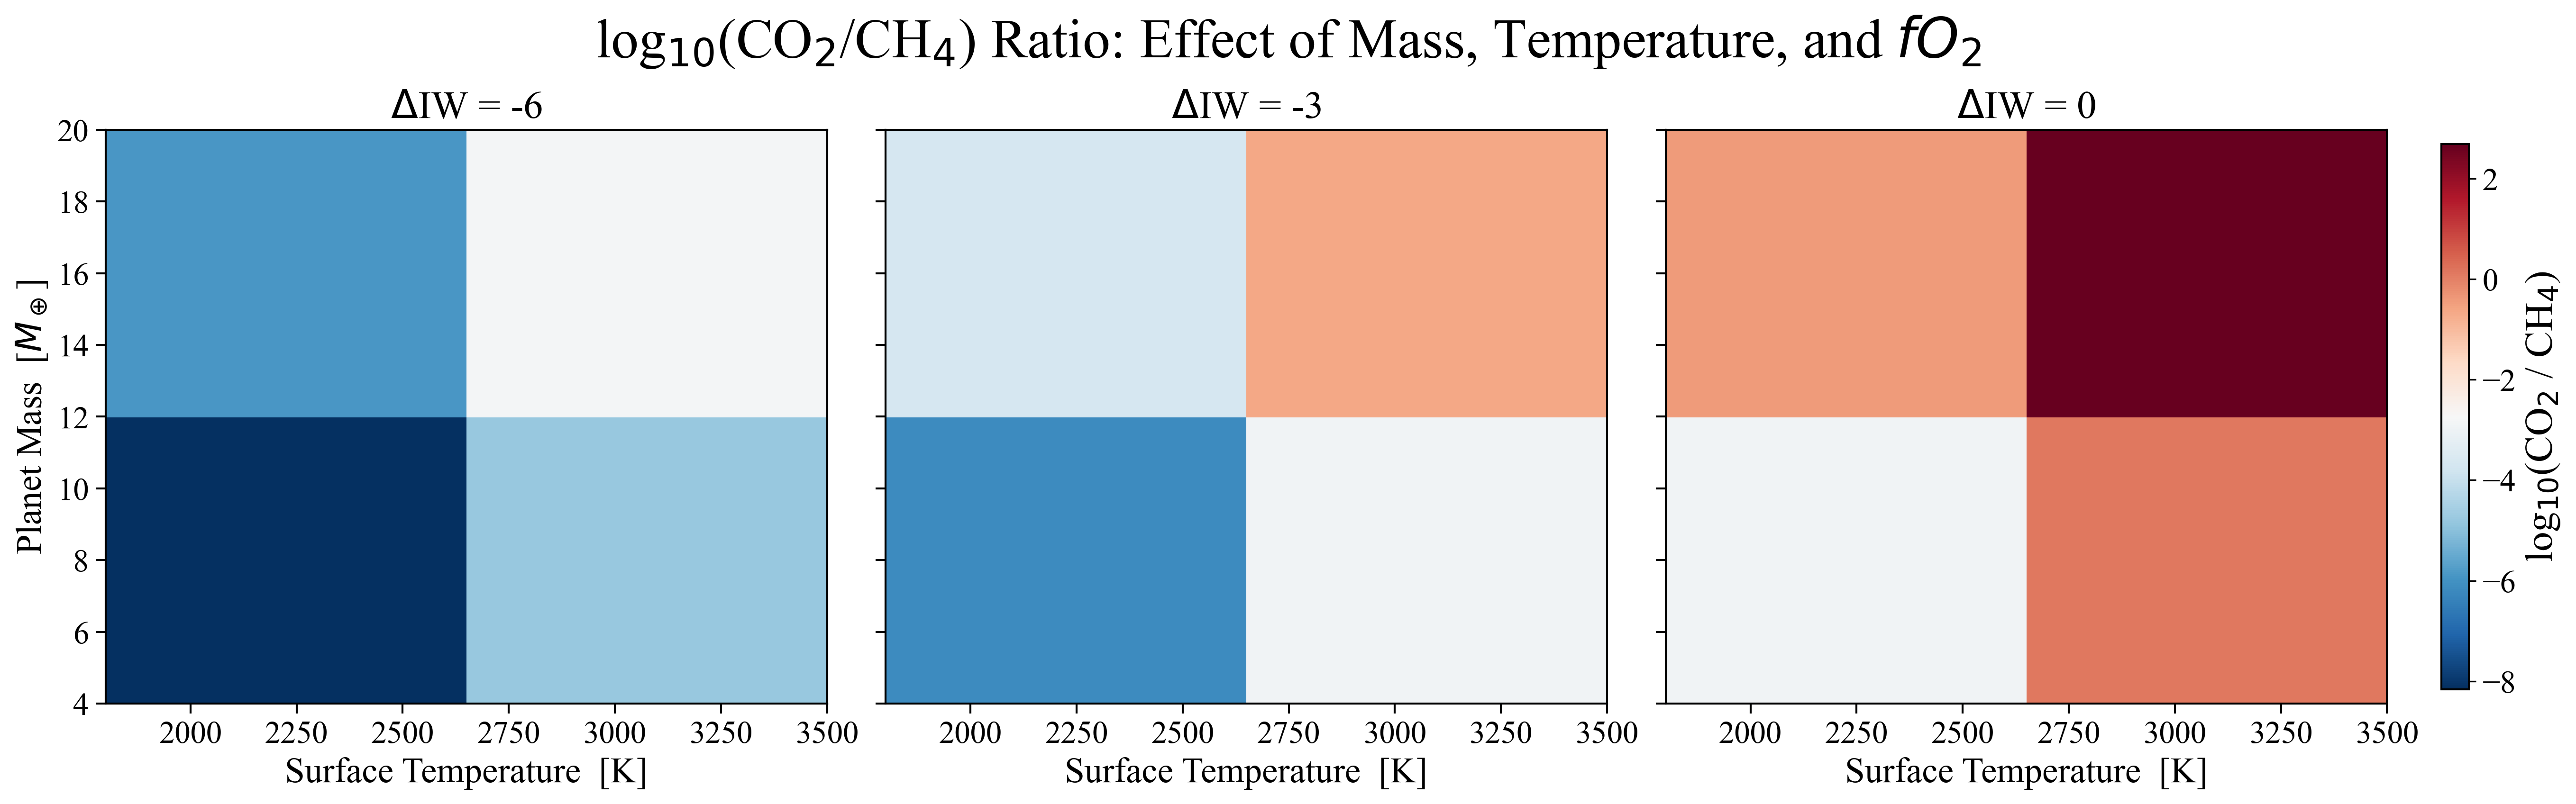

In [6]:
import logging
import numpy as np
import optimistix as optx
import matplotlib.pyplot as plt

# atmodeller imports
from atmodeller import (
    InteriorAtmosphere,
    Planet,
    SolverParameters,
    debug_logger,
)
from atmodeller.thermodata import IronWustiteBuffer
from atmodeller.eos import get_eos_models
from atmodeller.solubility import get_solubility_models
from atmodeller import Species, SpeciesCollection
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
from matplotlib import colormaps
import numpy as np
import pandas as pd


# --------------------------------------------------------------------
# 1. SETUP & LOGGING
# --------------------------------------------------------------------
logger = debug_logger()
logger.setLevel(logging.INFO)

# Constants for scaling
M_EARTH = 5.972e24  # kg
R_EARTH = 6.371e6   # m

# --------------------------------------------------------------------
# 3. COLLECTION & BUDGET
# --------------------------------------------------------------------

# Fixed volatile budget (You can also make this a function of planet mass if desired)
H_mass = 0.01 * planet_mass
mass_constraints = get_enriched_budget(H_mass)

solver = optx.LevenbergMarquardt
solver_parameters = SolverParameters(solver=solver)

# --------------------------------------------------------------------
# 4. PARAMETER GRIDS
# --------------------------------------------------------------------

# 1. Oxygen Fugacity (The 3 scenarios you requested)
dIW_scenarios = [-6, -3, 0]

# 2. X-axis: Temperature
Ts = np.linspace(1800, 3500, 2)

# 3. Y-axis: Planet Mass (in Earth Masses)
# We define a range, e.g., 0.1 Earths to 10 Earths
Ms_earth_units = np.linspace(4, 20, 2)

# --------------------------------------------------------------------
# 5. SOLVER FUNCTION
# --------------------------------------------------------------------

def solve_point(T_surf, Mass_earth_units, dIW_val):
    """
    Calculates radius from mass, solves equilibrium, returns log10(CO2/CH4).
    """
    
    # 1. Convert Mass to kg
    M_planet_kg = Mass_earth_units * M_EARTH
    
    # 2. Calculate Radius using your specific formula
    # surface_radius = 1.02 * (planet_mass / Earth_mass)**(0.252) * Earth_radius
    R_planet_m = 1.02 * (Mass_earth_units)**(0.252) * R_EARTH

    planet = Planet(
        surface_temperature=T_surf,
        planet_mass=M_planet_kg,
        surface_radius=R_planet_m,
        mantle_melt_fraction=1.0, # Assuming melt=1.0 based on context, adjust if needed
    )
    
    fO2 = {O2_rg.name: IronWustiteBuffer(dIW_val)}
    model = InteriorAtmosphere(species_real)

    try:
        model.solve(
            planet=planet,
            mass_constraints=mass_constraints,
            fugacity_constraints=fO2,
            solver_parameters=solver_parameters,
        )

        out = model.output
        df = out.to_dataframes()
        
        Xco2 = df["CO_g"]["atmosphere_moles"] 
        Xch4 = df["CH4_g"]["atmosphere_moles"]

        ratio = Xco2 / Xch4
        
        # Handle cases where CH4 might be 0 to avoid -inf
            
        return np.log10(ratio)
        
    except Exception as e:
        # print(f"Failed at T={T_surf}, M={Mass_earth_units}: {e}")
        return np.nan

# --------------------------------------------------------------------
# 6. CALCULATION LOOP
# --------------------------------------------------------------------
print("Starting simulation loop...")

# Storage dictionary: Key = dIW value, Value = 2D Numpy Array
results = {}

for dIW in dIW_scenarios:
    print(f"--- Processing dIW = {dIW} ---")
    
    # Create grid: Rows = Mass (Y), Cols = Temp (X)
    grid_data = np.zeros((len(Ms_earth_units), len(Ts)))
    
    for i, M_val in enumerate(Ms_earth_units):
        for j, T_val in enumerate(Ts):
            
            val = solve_point(T_val, M_val, dIW)
            grid_data[i, j] = val
            
    results[dIW] = grid_data

# ===========================================================
# 7. NATURE-STYLE PLOTTING
# ===========================================================
def set_master_nature_style():
    plt.rcdefaults()
    plt.rcParams["font.family"]        = "serif"
    plt.rcParams["font.serif"]         = ["Times New Roman", "DejaVu Serif"]
    plt.rcParams["axes.labelsize"]     = 18
    plt.rcParams["xtick.labelsize"]    = 16
    plt.rcParams["ytick.labelsize"]    = 16
    plt.rcParams["legend.fontsize"]    = 11
    plt.rcParams["axes.linewidth"]     = 1.0
    plt.rcParams["axes.grid"]          = True
    plt.rcParams["grid.linestyle"]     = ":"
    plt.rcParams["grid.linewidth"]     = 0.5
    plt.rcParams["grid.alpha"]         = 0.45
    plt.rcParams["axes.prop_cycle"]    = plt.cycler(color=colormaps["tab10"].colors)

set_master_nature_style()

# ------------------------------------------
# Figure setup
# ------------------------------------------
fig, axs = plt.subplots(
    1, 3,
    figsize=(18, 5),
    dpi=300,
    sharey=True,
    layout="constrained"
)

fig.suptitle(
    r"log$_{10}$(CO$_2$/CH$_4$) Ratio: Effect of Mass, Temperature, and $fO{_2}$",
    fontsize=28,
    x=0.5,
    y=1.1,
    ha="center"
)

extent = [Ts.min(), Ts.max(), Ms_earth_units.min(), Ms_earth_units.max()]

all_vals = np.array([results[k] for k in results]).flatten()
vmin, vmax = np.nanmin(all_vals), np.nanmax(all_vals)

# ------------------------------------------
# Plot each ΔIW scenario
# ------------------------------------------
for i, dIW in enumerate(dIW_scenarios):
    ax = axs[i]
    data = results[dIW]

    im = ax.imshow(
        data,
        origin="lower",
        aspect="auto",
        extent=extent,
        cmap="RdBu_r",
        vmin=vmin, vmax=vmax
    )

    # PANEL TITLE
    ax.set_title(f"$\Delta$IW = {dIW}", fontsize=20)

    # AXES
    ax.set_xlabel("Surface Temperature  [K]")
    ax.set_xlim(Ts.min(), Ts.max())

    if i == 0:
        ax.set_ylabel(r"Planet Mass  [$M_\oplus$]")

    # Spines
    for spine in ax.spines.values():
        spine.set_linewidth(1.0)

    # Clean heatmap (grid off)
    ax.grid(False)

    # Tick formatting
    ax.tick_params(direction="out", length=5, width=1)

# ------------------------------------------
# COLORBAR
# ------------------------------------------
cbar = fig.colorbar(
    im,
    ax=axs,
    shrink=0.95,
    pad=0.01
)
cbar.set_label(r"log$_{10}$(CO$_2$ / CH$_4$)", fontsize=20)

# Better tick formatting
cbar.ax.tick_params(labelsize=16)

plt.show()


<>:192: SyntaxWarning: invalid escape sequence '\D'
<>:192: SyntaxWarning: invalid escape sequence '\D'
/var/folders/l6/yw7hsmzx1czfjt3n32sfq_w00000gn/T/ipykernel_66046/1794091238.py:192: SyntaxWarning: invalid escape sequence '\D'
  ax.set_title(f"$\Delta$IW = {dIW}", fontsize=20)
[16:18:34 - atmodeller.classes             - INFO     ] - species = ('H2O_g: CombinedRealGas, SolubilityPowerLaw', 'H2_g: CombinedRealGas, SolubilityPowerLawLog10', 'O2_g: CombinedRealGas, NoSolubility', 'CO2_g: CombinedRealGas, _CO2_basalt_dixon95', 'CO_g: CombinedRealGas, _CO_basalt_yoshioka19', 'CH4_g: CombinedRealGas, _CH4_basalt_ardia13', 'N2_g: CombinedRealGas, _N2_basalt_libourel03', 'H3N_g: RedlichKwong49, NoSolubility', 'CHN_g: RedlichKwong49, NoSolubility', 'He_g: CombinedRealGas, SolubilityPowerLaw')
[16:18:34 - atmodeller.classes             - INFO     ] - Thermodynamic data requires temperatures between 200 K and 6000 K
[16:18:34 - atmodeller.classes             - INFO     ] - reactions = {0: '2

Starting simulation loop...
--- Processing dIW = -6 ---


[16:19:11 - atmodeller.classes             - INFO     ] - Solve complete: 1 (100.00%) successful model(s)
[16:19:11 - atmodeller.classes             - INFO     ] - Solver steps (max) = 88
[16:19:11 - atmodeller.output_core         - INFO     ] - Computing to_dataframes output
[16:19:11 - atmodeller.output_core         - INFO     ] - Computing asdict output
/var/folders/l6/yw7hsmzx1czfjt3n32sfq_w00000gn/T/ipykernel_66046/1794091238.py:127: FutureWarning: Calling float on a single element Series is deprecated and will raise a TypeError in the future. Use float(ser.iloc[0]) instead
  grid_data[i, j] = val
[16:19:16 - atmodeller.classes             - INFO     ] - species = ('H2O_g: CombinedRealGas, SolubilityPowerLaw', 'H2_g: CombinedRealGas, SolubilityPowerLawLog10', 'O2_g: CombinedRealGas, NoSolubility', 'CO2_g: CombinedRealGas, _CO2_basalt_dixon95', 'CO_g: CombinedRealGas, _CO_basalt_yoshioka19', 'CH4_g: CombinedRealGas, _CH4_basalt_ardia13', 'N2_g: CombinedRealGas, _N2_basalt_libourel0

--- Processing dIW = -3 ---


[16:20:25 - atmodeller.classes             - INFO     ] - species = ('H2O_g: CombinedRealGas, SolubilityPowerLaw', 'H2_g: CombinedRealGas, SolubilityPowerLawLog10', 'O2_g: CombinedRealGas, NoSolubility', 'CO2_g: CombinedRealGas, _CO2_basalt_dixon95', 'CO_g: CombinedRealGas, _CO_basalt_yoshioka19', 'CH4_g: CombinedRealGas, _CH4_basalt_ardia13', 'N2_g: CombinedRealGas, _N2_basalt_libourel03', 'H3N_g: RedlichKwong49, NoSolubility', 'CHN_g: RedlichKwong49, NoSolubility', 'He_g: CombinedRealGas, SolubilityPowerLaw')
[16:20:25 - atmodeller.classes             - INFO     ] - Thermodynamic data requires temperatures between 200 K and 6000 K
[16:20:25 - atmodeller.classes             - INFO     ] - reactions = {0: '2.0 H2_g + 2.0 CO_g = 1.0 CO2_g + 1.0 CH4_g',
 1: '1.0 H2_g + 1.0 CO2_g = 1.0 H2O_g + 1.0 CO_g',
 2: '1.5 H2_g + 0.5 N2_g = 1.0 H3N_g',
 3: '0.5 H2_g + 2.0 CO_g + 0.5 N2_g = 1.0 CO2_g + 1.0 CHN_g',
 4: '2.0 CO2_g = 1.0 O2_g + 2.0 CO_g'}
[16:20:25 - atmodeller.classes             - IN

--- Processing dIW = 0 ---


[16:21:38 - atmodeller.classes             - INFO     ] - species = ('H2O_g: CombinedRealGas, SolubilityPowerLaw', 'H2_g: CombinedRealGas, SolubilityPowerLawLog10', 'O2_g: CombinedRealGas, NoSolubility', 'CO2_g: CombinedRealGas, _CO2_basalt_dixon95', 'CO_g: CombinedRealGas, _CO_basalt_yoshioka19', 'CH4_g: CombinedRealGas, _CH4_basalt_ardia13', 'N2_g: CombinedRealGas, _N2_basalt_libourel03', 'H3N_g: RedlichKwong49, NoSolubility', 'CHN_g: RedlichKwong49, NoSolubility', 'He_g: CombinedRealGas, SolubilityPowerLaw')
[16:21:38 - atmodeller.classes             - INFO     ] - Thermodynamic data requires temperatures between 200 K and 6000 K
[16:21:38 - atmodeller.classes             - INFO     ] - reactions = {0: '2.0 H2_g + 2.0 CO_g = 1.0 CO2_g + 1.0 CH4_g',
 1: '1.0 H2_g + 1.0 CO2_g = 1.0 H2O_g + 1.0 CO_g',
 2: '1.5 H2_g + 0.5 N2_g = 1.0 H3N_g',
 3: '0.5 H2_g + 2.0 CO_g + 0.5 N2_g = 1.0 CO2_g + 1.0 CHN_g',
 4: '2.0 CO2_g = 1.0 O2_g + 2.0 CO_g'}
[16:21:38 - atmodeller.classes             - IN

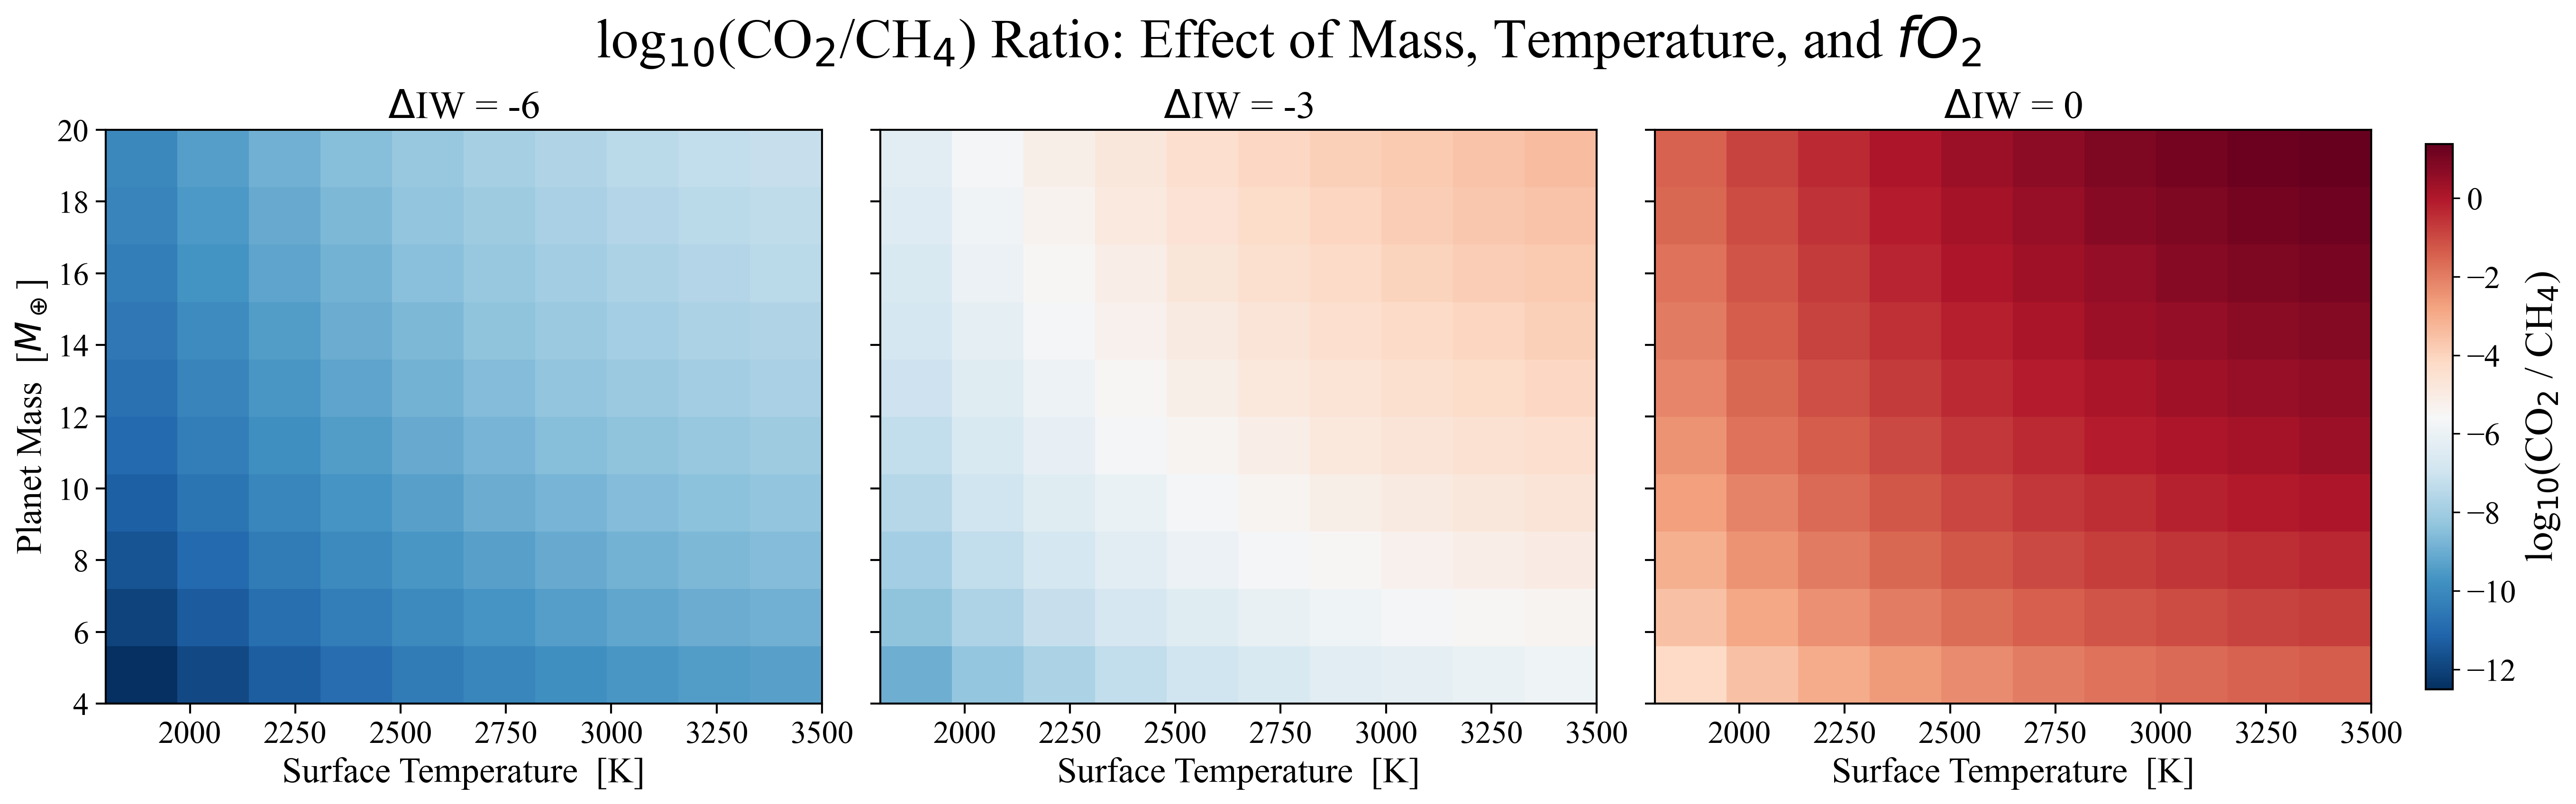

In [6]:
import logging
import numpy as np
import optimistix as optx
import matplotlib.pyplot as plt

# atmodeller imports
from atmodeller import (
    InteriorAtmosphere,
    Planet,
    SolverParameters,
    debug_logger,
)
from atmodeller.thermodata import IronWustiteBuffer
from atmodeller.eos import get_eos_models
from atmodeller.solubility import get_solubility_models
from atmodeller import Species, SpeciesCollection
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
from matplotlib import colormaps
import numpy as np
import pandas as pd


# --------------------------------------------------------------------
# 1. SETUP & LOGGING
# --------------------------------------------------------------------
logger = debug_logger()
logger.setLevel(logging.INFO)

# Constants for scaling
M_EARTH = 5.972e24  # kg
R_EARTH = 6.371e6   # m

# --------------------------------------------------------------------
# 3. COLLECTION & BUDGET
# --------------------------------------------------------------------

# Fixed volatile budget (You can also make this a function of planet mass if desired)
H_mass = 0.01 * planet_mass
mass_constraints = get_enriched_budget(H_mass)

solver = optx.LevenbergMarquardt
solver_parameters = SolverParameters(solver=solver)

# --------------------------------------------------------------------
# 4. PARAMETER GRIDS
# --------------------------------------------------------------------

# 1. Oxygen Fugacity (The 3 scenarios you requested)
dIW_scenarios = [-6, -3, 0]

# 2. X-axis: Temperature
Ts = np.linspace(1800, 3500, 10)

# 3. Y-axis: Planet Mass (in Earth Masses)
# We define a range, e.g., 0.1 Earths to 10 Earths
Ms_earth_units = np.linspace(4, 20, 10)

# --------------------------------------------------------------------
# 5. SOLVER FUNCTION
# --------------------------------------------------------------------

def solve_point(T_surf, Mass_earth_units, dIW_val):
    """
    Calculates radius from mass, solves equilibrium, returns log10(CO2/CH4).
    """
    
    # 1. Convert Mass to kg
    M_planet_kg = Mass_earth_units * M_EARTH
    
    # 2. Calculate Radius using your specific formula
    # surface_radius = 1.02 * (planet_mass / Earth_mass)**(0.252) * Earth_radius
    R_planet_m = 1.02 * (Mass_earth_units)**(0.252) * R_EARTH

    planet = Planet(
        surface_temperature=T_surf,
        planet_mass=M_planet_kg,
        surface_radius=R_planet_m,
        mantle_melt_fraction=1.0, # Assuming melt=1.0 based on context, adjust if needed
    )
    
    fO2 = {O2_rg.name: IronWustiteBuffer(dIW_val)}
    model = InteriorAtmosphere(species_real)

    try:
        model.solve(
            planet=planet,
            mass_constraints=mass_constraints,
            fugacity_constraints=fO2,
            solver_parameters=solver_parameters,
        )

        out = model.output
        df = out.to_dataframes()
        
        Xco2 = df["CO2_g"]["atmosphere_moles"] 
        Xch4 = df["CH4_g"]["atmosphere_moles"]

        ratio = Xco2 / Xch4
        
        # Handle cases where CH4 might be 0 to avoid -inf
            
        return np.log10(ratio)
        
    except Exception as e:
        # print(f"Failed at T={T_surf}, M={Mass_earth_units}: {e}")
        return np.nan

# --------------------------------------------------------------------
# 6. CALCULATION LOOP
# --------------------------------------------------------------------
print("Starting simulation loop...")

# Storage dictionary: Key = dIW value, Value = 2D Numpy Array
results = {}

for dIW in dIW_scenarios:
    print(f"--- Processing dIW = {dIW} ---")
    
    # Create grid: Rows = Mass (Y), Cols = Temp (X)
    grid_data = np.zeros((len(Ms_earth_units), len(Ts)))
    
    for i, M_val in enumerate(Ms_earth_units):
        for j, T_val in enumerate(Ts):
            
            val = solve_point(T_val, M_val, dIW)
            grid_data[i, j] = val
            
    results[dIW] = grid_data

# ===========================================================
# 7. NATURE-STYLE PLOTTING
# ===========================================================
def set_master_nature_style():
    plt.rcdefaults()
    plt.rcParams["font.family"]        = "serif"
    plt.rcParams["font.serif"]         = ["Times New Roman", "DejaVu Serif"]
    plt.rcParams["axes.labelsize"]     = 18
    plt.rcParams["xtick.labelsize"]    = 16
    plt.rcParams["ytick.labelsize"]    = 16
    plt.rcParams["legend.fontsize"]    = 11
    plt.rcParams["axes.linewidth"]     = 1.0
    plt.rcParams["axes.grid"]          = True
    plt.rcParams["grid.linestyle"]     = ":"
    plt.rcParams["grid.linewidth"]     = 0.5
    plt.rcParams["grid.alpha"]         = 0.45
    plt.rcParams["axes.prop_cycle"]    = plt.cycler(color=colormaps["tab10"].colors)

set_master_nature_style()

# ------------------------------------------
# Figure setup
# ------------------------------------------
fig, axs = plt.subplots(
    1, 3,
    figsize=(18, 5),
    dpi=300,
    sharey=True,
    layout="constrained"
)

fig.suptitle(
    r"log$_{10}$(CO$_2$/CH$_4$) Ratio: Effect of Mass, Temperature, and $fO{_2}$",
    fontsize=28,
    x=0.5,
    y=1.1,
    ha="center"
)

extent = [Ts.min(), Ts.max(), Ms_earth_units.min(), Ms_earth_units.max()]

all_vals = np.array([results[k] for k in results]).flatten()
vmin, vmax = np.nanmin(all_vals), np.nanmax(all_vals)

# ------------------------------------------
# Plot each ΔIW scenario
# ------------------------------------------
for i, dIW in enumerate(dIW_scenarios):
    ax = axs[i]
    data = results[dIW]

    im = ax.imshow(
        data,
        origin="lower",
        aspect="auto",
        extent=extent,
        cmap="RdBu_r",
        vmin=vmin, vmax=vmax
    )

    # PANEL TITLE
    ax.set_title(f"$\Delta$IW = {dIW}", fontsize=20)

    # AXES
    ax.set_xlabel("Surface Temperature  [K]")
    ax.set_xlim(Ts.min(), Ts.max())

    if i == 0:
        ax.set_ylabel(r"Planet Mass  [$M_\oplus$]")

    # Spines
    for spine in ax.spines.values():
        spine.set_linewidth(1.0)

    # Clean heatmap (grid off)
    ax.grid(False)

    # Tick formatting
    ax.tick_params(direction="out", length=5, width=1)

# ------------------------------------------
# COLORBAR
# ------------------------------------------
cbar = fig.colorbar(
    im,
    ax=axs,
    shrink=0.95,
    pad=0.01
)
cbar.set_label(r"log$_{10}$(CO$_2$ / CH$_4$)", fontsize=20)

# Better tick formatting
cbar.ax.tick_params(labelsize=16)

plt.show()


In [6]:
import logging
import numpy as np
import optimistix as optx
import matplotlib.pyplot as plt

# atmodeller imports
from atmodeller import (
    InteriorAtmosphere,
    Planet,
    SolverParameters,
    debug_logger,
)
from atmodeller.thermodata import IronWustiteBuffer
from atmodeller.eos import get_eos_models
from atmodeller.solubility import get_solubility_models
from atmodeller import Species, SpeciesCollection
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
from matplotlib import colormaps
import numpy as np
import pandas as pd


# --------------------------------------------------------------------
# 1. SETUP & LOGGING
# --------------------------------------------------------------------
logger = debug_logger()
logger.setLevel(logging.INFO)

# Constants for scaling
M_EARTH = 5.972e24  # kg
R_EARTH = 6.371e6   # m

# --------------------------------------------------------------------
# 3. COLLECTION & BUDGET
# --------------------------------------------------------------------

# Fixed volatile budget (You can also make this a function of planet mass if desired)
H_mass = 0.01 * planet_mass
mass_constraints = get_enriched_budget(H_mass)

solver = optx.LevenbergMarquardt
solver_parameters = SolverParameters(solver=solver)

# --------------------------------------------------------------------
# 4. PARAMETER GRIDS
# --------------------------------------------------------------------

# 1. Oxygen Fugacity (The 3 scenarios you requested)
dIW_scenarios = [-6, -3, 0]

# 2. X-axis: Temperature
Ts = np.linspace(1800, 3500, 10)

# 3. Y-axis: Planet Mass (in Earth Masses)
# We define a range, e.g., 0.1 Earths to 10 Earths
Ms_earth_units = np.linspace(4, 20, 10)

# --------------------------------------------------------------------
# 5. SOLVER FUNCTION
# --------------------------------------------------------------------

def solve_point(T_surf, Mass_earth_units, dIW_val):
    """
    Calculates radius from mass, solves equilibrium, returns log10(CO2/CH4).
    """
    
    # 1. Convert Mass to kg
    M_planet_kg = Mass_earth_units * M_EARTH
    
    # 2. Calculate Radius using your specific formula
    # surface_radius = 1.02 * (planet_mass / Earth_mass)**(0.252) * Earth_radius
    R_planet_m = 1.02 * (Mass_earth_units)**(0.252) * R_EARTH

    planet = Planet(
        surface_temperature=T_surf,
        planet_mass=M_planet_kg,
        surface_radius=R_planet_m,
        mantle_melt_fraction=1.0, # Assuming melt=1.0 based on context, adjust if needed
    )
    
    fO2 = {O2_rg.name: IronWustiteBuffer(dIW_val)}
    model = InteriorAtmosphere(species_real)

    try:
        model.solve(
            planet=planet,
            mass_constraints=mass_constraints,
            fugacity_constraints=fO2,
            solver_parameters=solver_parameters,
        )

        out = model.output
        df = out.to_dataframes()
        
        Xco2 = df["CO2_g"]["atmosphere_moles"] 
        Xch4 = df["CH4_g"]["atmosphere_moles"]

        ratio = Xco2 / Xch4
        
        # Handle cases where CH4 might be 0 to avoid -inf
            
        return np.log10(ratio)
        
    except Exception as e:
        # print(f"Failed at T={T_surf}, M={Mass_earth_units}: {e}")
        return np.nan

# --------------------------------------------------------------------
# 6. CALCULATION LOOP
# --------------------------------------------------------------------
print("Starting simulation loop...")

# Storage dictionary: Key = dIW value, Value = 2D Numpy Array
results = {}

for dIW in dIW_scenarios:
    print(f"--- Processing dIW = {dIW} ---")
    
    # Create grid: Rows = Mass (Y), Cols = Temp (X)
    grid_data = np.zeros((len(Ms_earth_units), len(Ts)))
    
    for i, M_val in enumerate(Ms_earth_units):
        for j, T_val in enumerate(Ts):
            
            val = solve_point(T_val, M_val, dIW)
            grid_data[i, j] = val
            
    results[dIW] = grid_data

# ===========================================================
# 7. NATURE-STYLE PLOTTING — SEPARATE FIGURES
# ===========================================================
def set_master_nature_style():
    plt.rcdefaults()
    plt.rcParams.update({
        "font.family": "serif",
        "font.serif": ["Times New Roman", "DejaVu Serif"],
        "axes.titlesize": 26,
        "axes.labelsize": 22,
        "xtick.labelsize": 18,
        "ytick.labelsize": 18,
        "axes.linewidth": 1.2,
        "axes.grid": False,
    })

set_master_nature_style()

# ------------------------------------------
# GLOBAL COLOR SCALE (CRITICAL)
# ------------------------------------------
extent = [Ts.min(), Ts.max(), Ms_earth_units.min(), Ms_earth_units.max()]
all_vals = np.array([results[k] for k in results]).flatten()
vmin, vmax = np.nanmin(all_vals), np.nanmax(all_vals)

# ------------------------------------------
# ONE FIGURE PER ΔIW SCENARIO
# ------------------------------------------
for dIW in dIW_scenarios:

    fig, ax = plt.subplots(
        figsize=(9, 7),
        dpi=300
    )

    im = ax.imshow(
        results[dIW],
        origin="lower",
        aspect="auto",
        extent=extent,
        cmap="RdBu_r",
        vmin=vmin,
        vmax=vmax
    )

    # -------------------------------
    # TITLES & LABELS
    # -------------------------------
    ax.set_title(
        rf"log$_{{10}}$(CO$_2$/CH$_4$) Ratio ($\Delta$IW = {dIW})",
        pad=16
    )

    ax.set_xlabel("Surface Temperature  [K]")
    ax.set_ylabel(r"Planet Mass  [$M_\oplus$]")

    ax.set_xlim(Ts.min(), Ts.max())
    ax.set_ylim(Ms_earth_units.min(), Ms_earth_units.max())

    ax.tick_params(direction="out", length=6, width=1.2)

    # -------------------------------
    # COLORBAR — RIGHT SIDE
    # -------------------------------
    cbar = fig.colorbar(
        im,
        ax=ax,
        location="right",
        pad=0.03
    )

    cbar.set_label(
        r"log$_{10}$(CO$_2$ / CH$_4$)",
        fontsize=20,
        rotation=90,
        labelpad=14
    )
    cbar.ax.tick_params(labelsize=16)

    # -------------------------------
    # SAVE & CLOSE
    # -------------------------------
    plt.savefig(
        f"logCO2_CH4_heatmap_IW{dIW}.png",
        bbox_inches="tight"
    )
    plt.close()


[13:41:46 - atmodeller.classes             - INFO     ] - species = ('H2O_g: CombinedRealGas, SolubilityPowerLaw', 'H2_g: CombinedRealGas, SolubilityPowerLawLog10', 'O2_g: CombinedRealGas, NoSolubility', 'CO2_g: CombinedRealGas, _CO2_basalt_dixon95', 'CO_g: CombinedRealGas, _CO_basalt_yoshioka19', 'CH4_g: CombinedRealGas, _CH4_basalt_ardia13', 'N2_g: CombinedRealGas, _N2_basalt_libourel03', 'H3N_g: RedlichKwong49, NoSolubility', 'CHN_g: RedlichKwong49, NoSolubility', 'He_g: CombinedRealGas, SolubilityPowerLaw')
[13:41:46 - atmodeller.classes             - INFO     ] - Thermodynamic data requires temperatures between 200 K and 6000 K
[13:41:46 - atmodeller.classes             - INFO     ] - reactions = {0: '2.0 H2_g + 2.0 CO_g = 1.0 CO2_g + 1.0 CH4_g',
 1: '1.0 H2_g + 1.0 CO2_g = 1.0 H2O_g + 1.0 CO_g',
 2: '1.5 H2_g + 0.5 N2_g = 1.0 H3N_g',
 3: '0.5 H2_g + 2.0 CO_g + 0.5 N2_g = 1.0 CO2_g + 1.0 CHN_g',
 4: '2.0 CO2_g = 1.0 O2_g + 2.0 CO_g'}
[13:41:46 - atmodeller.classes             - IN

Starting simulation loop...
--- Processing dIW = -6 ---


[13:42:22 - atmodeller.classes             - INFO     ] - Solve complete: 1 (100.00%) successful model(s)
[13:42:22 - atmodeller.classes             - INFO     ] - Solver steps (max) = 88
[13:42:22 - atmodeller.output_core         - INFO     ] - Computing to_dataframes output
[13:42:22 - atmodeller.output_core         - INFO     ] - Computing asdict output
/var/folders/l6/yw7hsmzx1czfjt3n32sfq_w00000gn/T/ipykernel_23107/1663895431.py:127: FutureWarning: Calling float on a single element Series is deprecated and will raise a TypeError in the future. Use float(ser.iloc[0]) instead
  grid_data[i, j] = val
[13:42:26 - atmodeller.classes             - INFO     ] - species = ('H2O_g: CombinedRealGas, SolubilityPowerLaw', 'H2_g: CombinedRealGas, SolubilityPowerLawLog10', 'O2_g: CombinedRealGas, NoSolubility', 'CO2_g: CombinedRealGas, _CO2_basalt_dixon95', 'CO_g: CombinedRealGas, _CO_basalt_yoshioka19', 'CH4_g: CombinedRealGas, _CH4_basalt_ardia13', 'N2_g: CombinedRealGas, _N2_basalt_libourel0

--- Processing dIW = -3 ---


[13:43:35 - atmodeller.classes             - INFO     ] - species = ('H2O_g: CombinedRealGas, SolubilityPowerLaw', 'H2_g: CombinedRealGas, SolubilityPowerLawLog10', 'O2_g: CombinedRealGas, NoSolubility', 'CO2_g: CombinedRealGas, _CO2_basalt_dixon95', 'CO_g: CombinedRealGas, _CO_basalt_yoshioka19', 'CH4_g: CombinedRealGas, _CH4_basalt_ardia13', 'N2_g: CombinedRealGas, _N2_basalt_libourel03', 'H3N_g: RedlichKwong49, NoSolubility', 'CHN_g: RedlichKwong49, NoSolubility', 'He_g: CombinedRealGas, SolubilityPowerLaw')
[13:43:35 - atmodeller.classes             - INFO     ] - Thermodynamic data requires temperatures between 200 K and 6000 K
[13:43:35 - atmodeller.classes             - INFO     ] - reactions = {0: '2.0 H2_g + 2.0 CO_g = 1.0 CO2_g + 1.0 CH4_g',
 1: '1.0 H2_g + 1.0 CO2_g = 1.0 H2O_g + 1.0 CO_g',
 2: '1.5 H2_g + 0.5 N2_g = 1.0 H3N_g',
 3: '0.5 H2_g + 2.0 CO_g + 0.5 N2_g = 1.0 CO2_g + 1.0 CHN_g',
 4: '2.0 CO2_g = 1.0 O2_g + 2.0 CO_g'}
[13:43:35 - atmodeller.classes             - IN

--- Processing dIW = 0 ---


[13:44:48 - atmodeller.classes             - INFO     ] - species = ('H2O_g: CombinedRealGas, SolubilityPowerLaw', 'H2_g: CombinedRealGas, SolubilityPowerLawLog10', 'O2_g: CombinedRealGas, NoSolubility', 'CO2_g: CombinedRealGas, _CO2_basalt_dixon95', 'CO_g: CombinedRealGas, _CO_basalt_yoshioka19', 'CH4_g: CombinedRealGas, _CH4_basalt_ardia13', 'N2_g: CombinedRealGas, _N2_basalt_libourel03', 'H3N_g: RedlichKwong49, NoSolubility', 'CHN_g: RedlichKwong49, NoSolubility', 'He_g: CombinedRealGas, SolubilityPowerLaw')
[13:44:48 - atmodeller.classes             - INFO     ] - Thermodynamic data requires temperatures between 200 K and 6000 K
[13:44:48 - atmodeller.classes             - INFO     ] - reactions = {0: '2.0 H2_g + 2.0 CO_g = 1.0 CO2_g + 1.0 CH4_g',
 1: '1.0 H2_g + 1.0 CO2_g = 1.0 H2O_g + 1.0 CO_g',
 2: '1.5 H2_g + 0.5 N2_g = 1.0 H3N_g',
 3: '0.5 H2_g + 2.0 CO_g + 0.5 N2_g = 1.0 CO2_g + 1.0 CHN_g',
 4: '2.0 CO2_g = 1.0 O2_g + 2.0 CO_g'}
[13:44:48 - atmodeller.classes             - IN